# 04 · Sensitivity of flood extent and exposure to detection settings

Research question (iii). One parameter is varied at a time around the defaults (VH drop −3 dB, VH below the per-scene Otsu value, HAND < 15 m, slope < 5°, JRC permanent water ≥ 10 months, patches ≥ 8 px). To isolate each effect the Otsu value is held fixed at its default for the date. Three dates: **16 June** (track 41 — same scene as the MBRSC reference), **18 June** (track 77 — nearest full-coverage scene to the ALOS-2 reference of 22 June) and **30 June** (track 77, largest extent). Outputs: flood area, built-up within 50 m, and agreement (F1) with the reference where one exists.

In [1]:
import sys, pathlib, time
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
import config, classify as C

st = C.static()
built = (st["worldcover"] == 50) & st["district"]
REF = config.DATA_PROCESSED / "reference_nagaon.gpkg"
refs = {"mbrsc_s1_20220616": C.rasterize_gdf(gpd.read_file(REF, layer="mbrsc_s1_20220616")).astype(bool),
        "eosrs_alos2_20220622": C.rasterize_gdf(gpd.read_file(REF, layer="eosrs_alos2_20220622")).astype(bool)}
DATES = {("2022-06-16", 41): "mbrsc_s1_20220616",
         ("2022-06-18", 77): "eosrs_alos2_20220622",
         ("2022-06-30", 77): None}

SWEEPS = {
    "diff_db":     [-1.0, -1.5, -2.0, -2.5, -3.0, -3.5, -4.0, -5.0, -6.0],
    "vh_db":       [-17.0, -18.0, -19.0, -20.0, -21.0, -22.0, -23.0, -24.0],
    "hand_m":      [5, 10, 15, 20, 30, 1000],
    "slope_deg":   [2, 3, 5, 10, 90],
    "perm_months": [13, 12, 10, 6, 3, 1],
    "mmu_px":      [1, 4, 8, 16, 30, 100],
    "pol":         ["VH", "VV"],
}
DEFAULTS = {k: config.DEFAULT_PARAMS[k] for k in SWEEPS if k in config.DEFAULT_PARAMS}

In [2]:
rows = []
t0 = time.time()
for (date, orb), ref_name in DATES.items():
    s1 = C.load_s1(date, orb)
    _, info = C.classify(s1, st=st)              # default run -> Otsu value for this date
    otsu_t = info["vh_threshold"]
    for param, values in SWEEPS.items():
        if param == "vh_db":                     # include the exact Otsu value as the default row
            values = sorted(set(values) | {round(otsu_t, 4)})
        for v in values:
            prm = {"vh_db": otsu_t, param: v}
            if param == "pol" and v == "VV":
                prm["vh_db"] = "otsu"           # VV needs its own automatic threshold
            cl, inf = C.classify(s1, prm, st=st)
            r = {"date": date, "track": orb, "param": param, "value": v,
                 "is_default": (v == round(otsu_t, 4)) if param == "vh_db" else (v == DEFAULTS.get(param)),
                 "vh_threshold": inf["vh_threshold"], "flood_km2": C.areas_km2(cl)["flood_km2"],
                 **C.built_exposed_km2(cl, built, (50,))}
            if ref_name:
                a = C.agreement(cl, refs[ref_name])
                r.update({"reference": ref_name, "f1": a["f1"], "precision": a["precision"], "recall": a["recall"]})
            rows.append(r)
    print(date, "otsu", round(otsu_t, 2), f"{time.time() - t0:.0f}s")
    del s1
sens = pd.DataFrame(rows)
sens.to_csv(config.OUT_TABLES / "sensitivity_one_at_a_time.csv", index=False)
sens.head()

2022-06-16 otsu -19.89 320s


2022-06-18 otsu -19.99 651s


2022-06-30 otsu -19.86 974s


,date,track,param,value,is_default,vh_threshold,flood_km2,exposed_50m_km2,reference,f1,precision,recall
0,2022-06-16,41,diff_db,-1.0,False,-19.891212,399.1736,3.5893,mbrsc_s1_20220616,0.440798,0.291125,0.907209
1,2022-06-16,41,diff_db,-1.5,False,-19.891212,375.2726,3.1790,mbrsc_s1_20220616,0.448847,0.301028,0.881899
2,2022-06-16,41,diff_db,-2.0,False,-19.891212,351.1889,2.7860,mbrsc_s1_20220616,0.455664,0.310934,0.852459
3,2022-06-16,41,diff_db,-2.5,False,-19.891212,327.0015,2.3774,mbrsc_s1_20220616,0.460886,0.320714,0.818716
4,2022-06-16,41,diff_db,-3.0,True,-19.891212,303.1313,2.0182,mbrsc_s1_20220616,0.464016,0.330049,0.781042


## One-at-a-time results

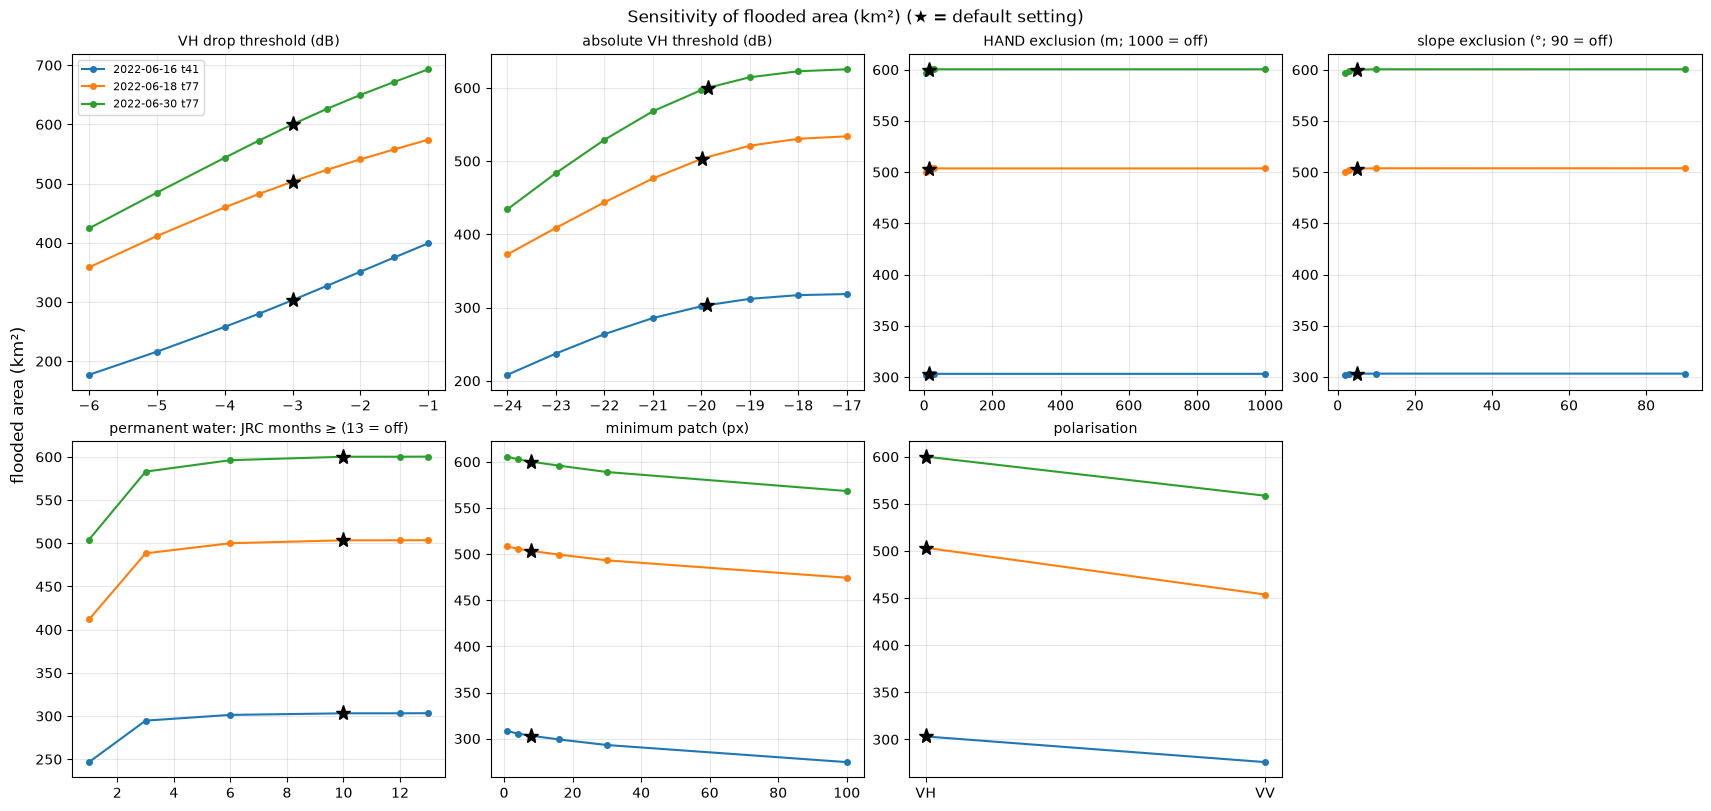

In [3]:
labels = {"diff_db": "VH drop threshold (dB)", "vh_db": "absolute VH threshold (dB)",
          "hand_m": "HAND exclusion (m; 1000 = off)", "slope_deg": "slope exclusion (°; 90 = off)",
          "perm_months": "permanent water: JRC months ≥ (13 = off)", "mmu_px": "minimum patch (px)",
          "pol": "polarisation"}
def panel_plot(metric, ylabel, fname, dates=DATES):
    fig, axes = plt.subplots(2, 4, figsize=(17, 8), constrained_layout=True)
    for ax, param in zip(axes.ravel(), SWEEPS):
        for (date, orb) in dates:
            d = sens[(sens.param == param) & (sens.date == date)]
            if metric not in d or d[metric].isna().all():
                continue
            x = d["value"].astype(str) if param == "pol" else d["value"]
            ax.plot(x, d[metric], "o-", ms=4, label=f"{date} t{orb}")
            dd = d[d.is_default]
            ax.plot(dd["value"].astype(str) if param == "pol" else dd["value"], dd[metric], "k*", ms=11, zorder=5)
        ax.set_title(labels[param], fontsize=10); ax.grid(alpha=.3)
    axes.ravel()[-1].axis("off")
    axes.ravel()[0].legend(fontsize=8)
    fig.supylabel(ylabel); fig.suptitle(f"Sensitivity of {ylabel} (★ = default setting)")
    fig.savefig(config.OUT_FIGURES / fname, dpi=150); plt.show()

panel_plot("flood_km2", "flooded area (km²)", "sensitivity_flood_area.png")

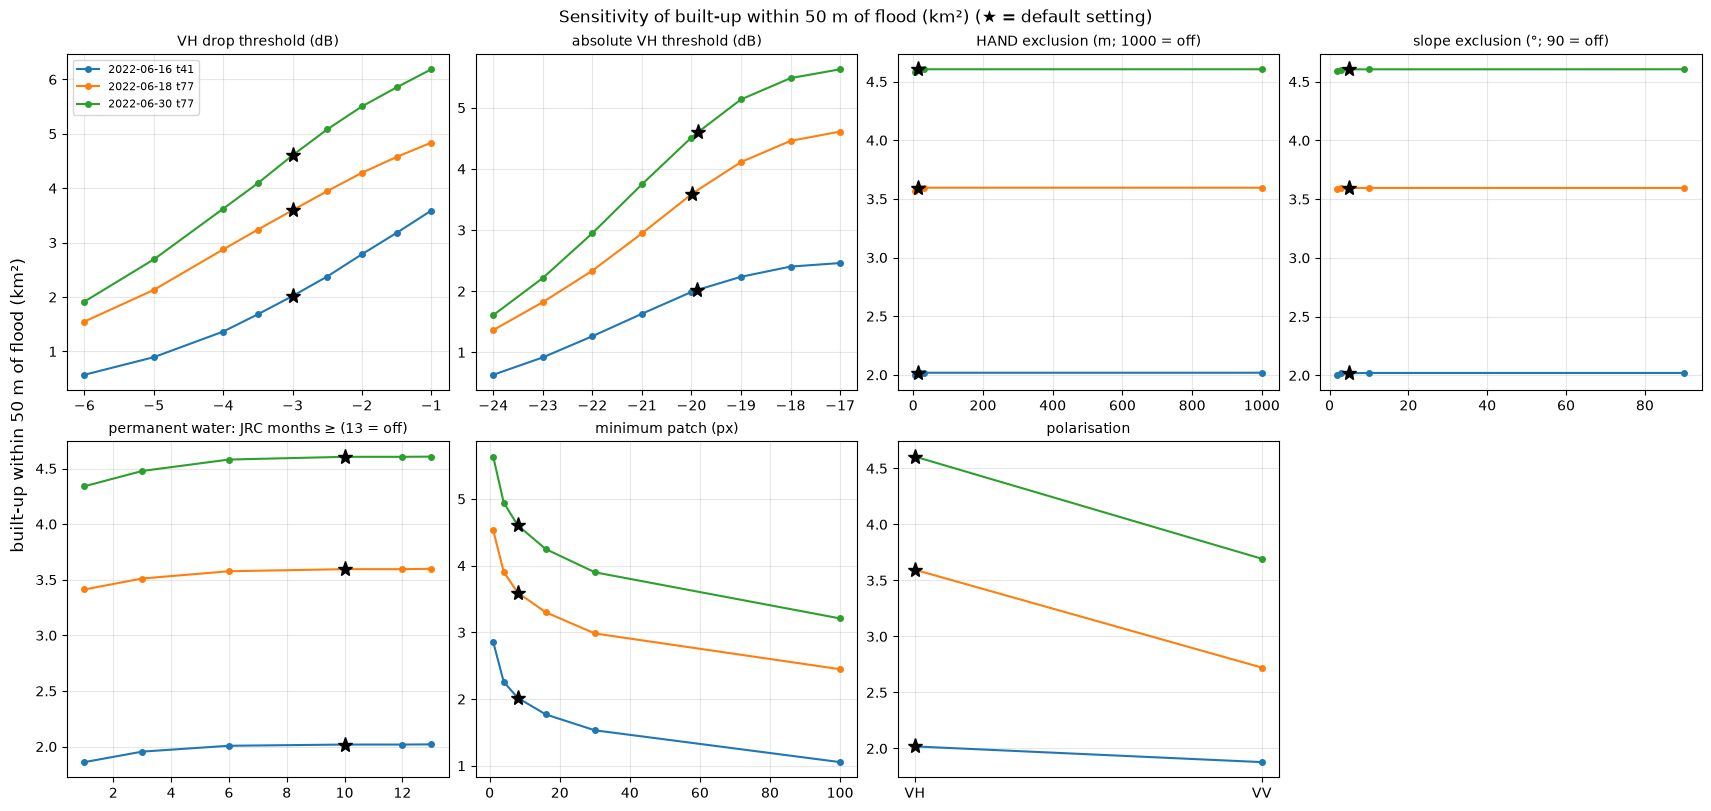

In [4]:
panel_plot("exposed_50m_km2", "built-up within 50 m of flood (km²)", "sensitivity_exposure.png")

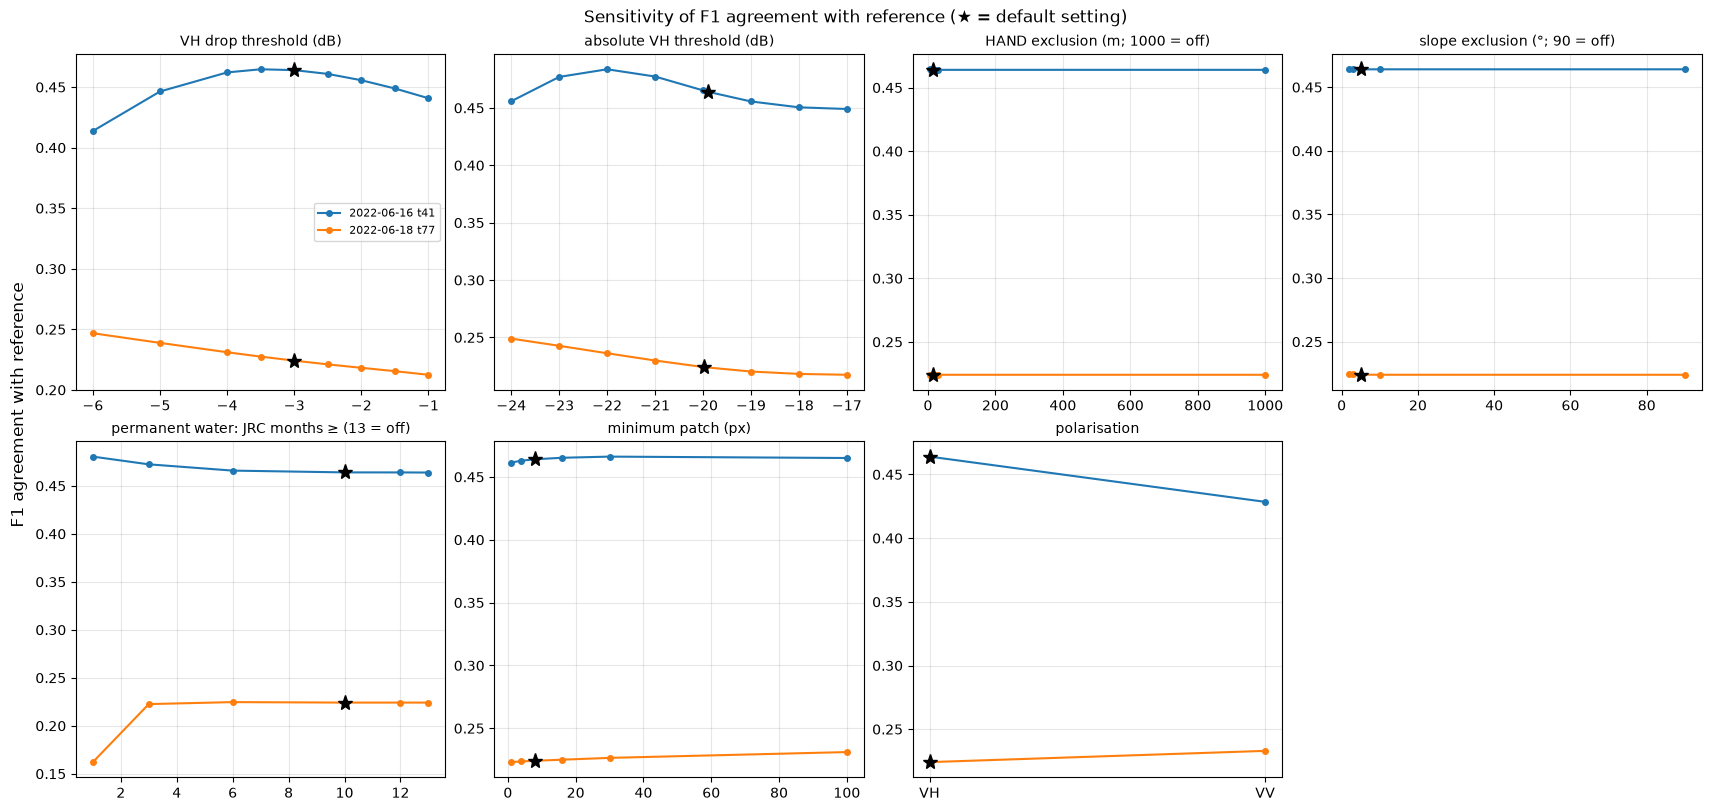

In [5]:
panel_plot("f1", "F1 agreement with reference", "sensitivity_f1.png",
           dates=[k for k, v in DATES.items() if v])

## Joint sweep of the two main thresholds (18 June, track 77)

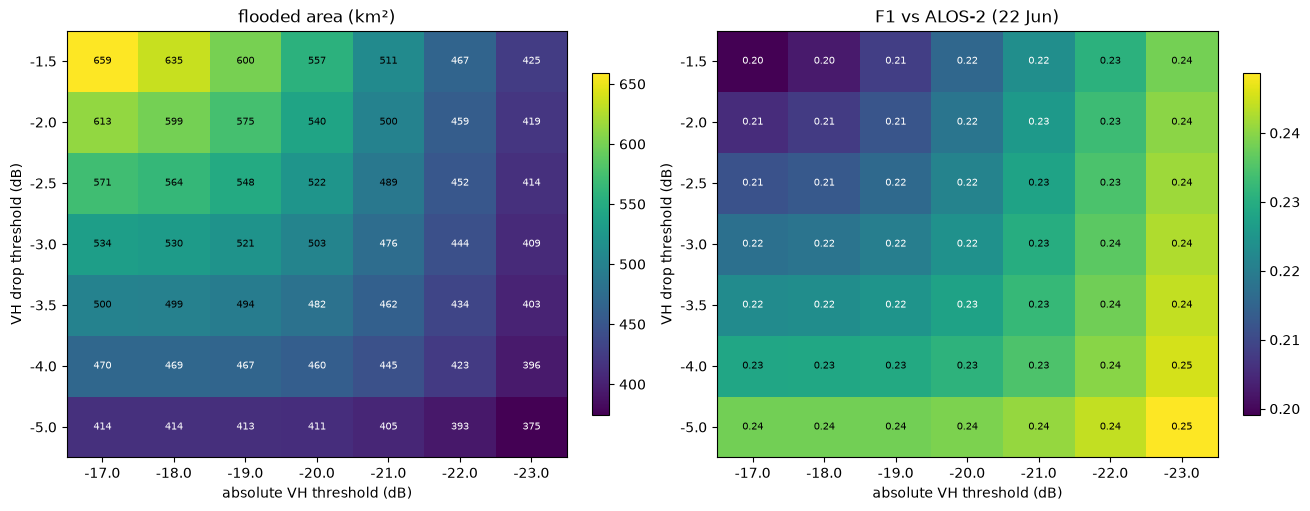

In [6]:
s1 = C.load_s1("2022-06-18", 77)
diffs = [-1.5, -2.0, -2.5, -3.0, -3.5, -4.0, -5.0]
vhs = [-17.0, -18.0, -19.0, -20.0, -21.0, -22.0, -23.0]
area = np.zeros((len(diffs), len(vhs))); f1 = np.zeros_like(area)
for i, dv in enumerate(diffs):
    for j, vv in enumerate(vhs):
        cl, _ = C.classify(s1, {"diff_db": dv, "vh_db": vv}, st=st)
        area[i, j] = C.areas_km2(cl)["flood_km2"]
        f1[i, j] = C.agreement(cl, refs["eosrs_alos2_20220622"])["f1"]
del s1
grid2 = pd.DataFrame([{"diff_db": d, "vh_db": v, "flood_km2": area[i, j], "f1_alos2": f1[i, j]}
                      for i, d in enumerate(diffs) for j, v in enumerate(vhs)])
grid2.to_csv(config.OUT_TABLES / "sensitivity_joint_18jun.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, z, title, fmt in [(axes[0], area, "flooded area (km²)", "{:.0f}"), (axes[1], f1, "F1 vs ALOS-2 (22 Jun)", "{:.2f}")]:
    im = ax.imshow(z, cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(vhs)), vhs); ax.set_yticks(range(len(diffs)), diffs)
    ax.set_xlabel("absolute VH threshold (dB)"); ax.set_ylabel("VH drop threshold (dB)"); ax.set_title(title)
    for i in range(len(diffs)):
        for j in range(len(vhs)):
            ax.text(j, i, fmt.format(z[i, j]), ha="center", va="center", fontsize=7,
                    color="w" if z[i, j] < z.mean() else "k")
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.savefig(config.OUT_FIGURES / "sensitivity_joint_18jun.png", dpi=150); plt.show()

## Summary: plausible range

Range of results when the two main thresholds vary over commonly used values (drop −2 to −4 dB, VH −19 to −22 dB), plus each one-at-a-time sweep's spread relative to the default.

In [7]:
plaus = grid2[(grid2.diff_db.between(-4, -2)) & (grid2.vh_db.between(-22, -19))]
print(f"18 June flood area over plausible thresholds: {plaus.flood_km2.min():.0f}-{plaus.flood_km2.max():.0f} km2 "
      f"(default {sens[(sens.date=='2022-06-18') & (sens.param=='diff_db') & sens.is_default].flood_km2.iloc[0]:.0f})")
summ = []
for (date, orb) in DATES:
    for param in SWEEPS:
        d = sens[(sens.date == date) & (sens.param == param)]
        base = d[d.is_default]
        if base.empty:
            continue
        b = base.iloc[0]
        summ.append({"date": date, "param": param,
                     "flood_min_km2": d.flood_km2.min(), "flood_max_km2": d.flood_km2.max(),
                     "flood_range_pct_of_default": 100 * (d.flood_km2.max() - d.flood_km2.min()) / b.flood_km2,
                     "exposed50_min_km2": d.exposed_50m_km2.min(), "exposed50_max_km2": d.exposed_50m_km2.max()})
summary = pd.DataFrame(summ).round(1)
summary.to_csv(config.OUT_TABLES / "sensitivity_summary.csv", index=False)
summary.pivot(index="param", columns="date", values="flood_range_pct_of_default")

18 June flood area over plausible thresholds: 423-575 km2 (default 503)


date,2022-06-16,2022-06-18,2022-06-30
param,,,
diff_db,73.3,42.9,44.8
hand_m,0.3,0.7,0.6
mmu_px,11.1,6.8,6.2
perm_months,18.7,18.2,16.0
pol,9.0,9.9,6.9
slope_deg,0.4,0.8,0.6
vh_db,36.4,32.0,31.8
